In [3]:

from pathlib import Path
import json
import csv
from collections import Counter, defaultdict

# ==========================================
# 1. Dataset paths
# ==========================================

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

TRAIN_ROOT = DATA_ROOT / "9_16_train_set" / "train"

EO_IMAGE = TRAIN_ROOT / "EO" / "image"
EO_LABEL = TRAIN_ROOT / "EO" / "label"

IR_IMAGE = TRAIN_ROOT / "IR" / "image"
IR_LABEL = TRAIN_ROOT / "IR" / "label"

GROUP_FILE = (
    DATA_ROOT
    / "SolarDefectDataset_supplement"
    / "train_groups.csv"
)

OUTPUT_DIR = DATA_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


# ==========================================
# 2. Count images and labels
# ==========================================

def get_files(folder, extensions):
    return sorted(
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in extensions
    )


eo_images = get_files(EO_IMAGE, {".jpg", ".jpeg"})
ir_images = get_files(IR_IMAGE, {".jpg", ".jpeg"})

eo_labels = get_files(EO_LABEL, {".json"})
ir_labels = get_files(IR_LABEL, {".json"})

print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)

print(f"EO Images : {len(eo_images)}")
print(f"IR Images : {len(ir_images)}")
print(f"EO Labels : {len(eo_labels)}")
print(f"IR Labels : {len(ir_labels)}")


# ==========================================
# 3. Check image pairing
# ==========================================

def get_stems(files):
    return {f.stem for f in files}


eo_ids = get_stems(eo_images)
ir_ids = get_stems(ir_images)

print("\n" + "=" * 50)
print("IMAGE PAIRING")
print("=" * 50)

print("Matched images :", len(eo_ids & ir_ids))
print("EO only        :", len(eo_ids - ir_ids))
print("IR only        :", len(ir_ids - eo_ids))

# Check image-label correspondence
for name, images, labels in [
    ("EO", eo_images, eo_labels),
    ("IR", ir_images, ir_labels)
]:
    missing_labels = get_stems(images) - get_stems(labels)
    missing_images = get_stems(labels) - get_stems(images)

    print(f"\n{name} missing labels:", len(missing_labels))
    print(f"{name} missing images:", len(missing_images))


# ==========================================
# 4. Analyze JSON annotations
# ==========================================

def analyze_annotations(label_folder):

    class_counts = Counter()
    image_counts = Counter()
    reason_counts = Counter()
    total_polygons = 0
    invalid_json = []

    for json_file in sorted(label_folder.glob("*.json")):

        try:
            with open(json_file, "r", encoding="utf-8") as f:
                data = json.load(f)

            shapes = data.get("shapes", [])
            labels_in_image = set()

            for shape in shapes:

                label = shape.get("label", "UNKNOWN")

                class_counts[label] += 1
                labels_in_image.add(label)
                total_polygons += 1

                reason = shape.get("reason")

                if label in ["crack", "hotspot"]:
                    if isinstance(reason, str) and reason.strip():
                        reason_counts[label] += 1

            for label in labels_in_image:
                image_counts[label] += 1

        except Exception as e:
            invalid_json.append((json_file.name, str(e)))

    return (
        class_counts,
        image_counts,
        reason_counts,
        total_polygons,
        invalid_json
    )


results = {}

for modality, folder in [
    ("EO", EO_LABEL),
    ("IR", IR_LABEL)
]:

    results[modality] = analyze_annotations(folder)

    classes, images, reasons, total, errors = results[modality]

    print("\n" + "=" * 50)
    print(f"{modality} ANNOTATION STATISTICS")
    print("=" * 50)

    print("Total polygons:", total)

    for label, count in classes.most_common():
        print(
            f"{label:15s} "
            f"Polygons: {count:5d} | "
            f"Images: {images[label]:5d}"
        )

    print("\nRoot cause descriptions:")

    for label, count in reasons.items():
        print(f"{label}: {count}")

    print("Invalid JSON files:", len(errors))

    if errors:
        print(errors[:5])


# ==========================================
# 5. Analyze training groups
# ==========================================

print("\n" + "=" * 50)
print("TRAINING GROUP DISTRIBUTION")
print("=" * 50)

group_counts = Counter()

with open(GROUP_FILE, "r", encoding="utf-8-sig") as f:

    reader = csv.DictReader(f)

    for row in reader:
        group_counts[row["group"]] += 1

for group, count in sorted(group_counts.items()):
    print(f"{group}: {count}")

print("Total frames:", sum(group_counts.values()))
print("Total groups:", len(group_counts))


# ==========================================
# 6. Save summary
# ==========================================

rows = []

for modality, result in results.items():

    classes, images, reasons, total, errors = result

    for label, count in classes.items():

        rows.append({
            "modality": modality,
            "class": label,
            "polygon_count": count,
            "image_count": images[label],
            "reason_count": reasons[label]
        })


import pandas as pd

df = pd.DataFrame(rows)

df.to_csv(
    OUTPUT_DIR / "class_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAnalysis completed.")
print("Output:", OUTPUT_DIR)


DATASET OVERVIEW
EO Images : 1046
IR Images : 1046
EO Labels : 1046
IR Labels : 1046

IMAGE PAIRING
Matched images : 1046
EO only        : 0
IR only        : 0

EO missing labels: 0
EO missing images: 0

IR missing labels: 0
IR missing images: 0

EO ANNOTATION STATISTICS
Total polygons: 29905
solar_panel     Polygons: 29553 | Images:  1046
crack           Polygons:   352 | Images:   258

Root cause descriptions:
crack: 352
Invalid JSON files: 0

IR ANNOTATION STATISTICS
Total polygons: 26701
solar_panel     Polygons: 26257 | Images:  1046
hotspot         Polygons:   444 | Images:   428

Root cause descriptions:
hotspot: 444
Invalid JSON files: 0

TRAINING GROUP DISTRIBUTION
G01: 288
G02: 197
G03: 23
G04: 305
G05: 11
G06: 4
G07: 58
G08: 7
G09: 18
G10: 72
G11: 40
G12: 23
Total frames: 1046
Total groups: 12

Analysis completed.
Output: C:\Users\Sharon\Downloads\VLPaicup\outputs


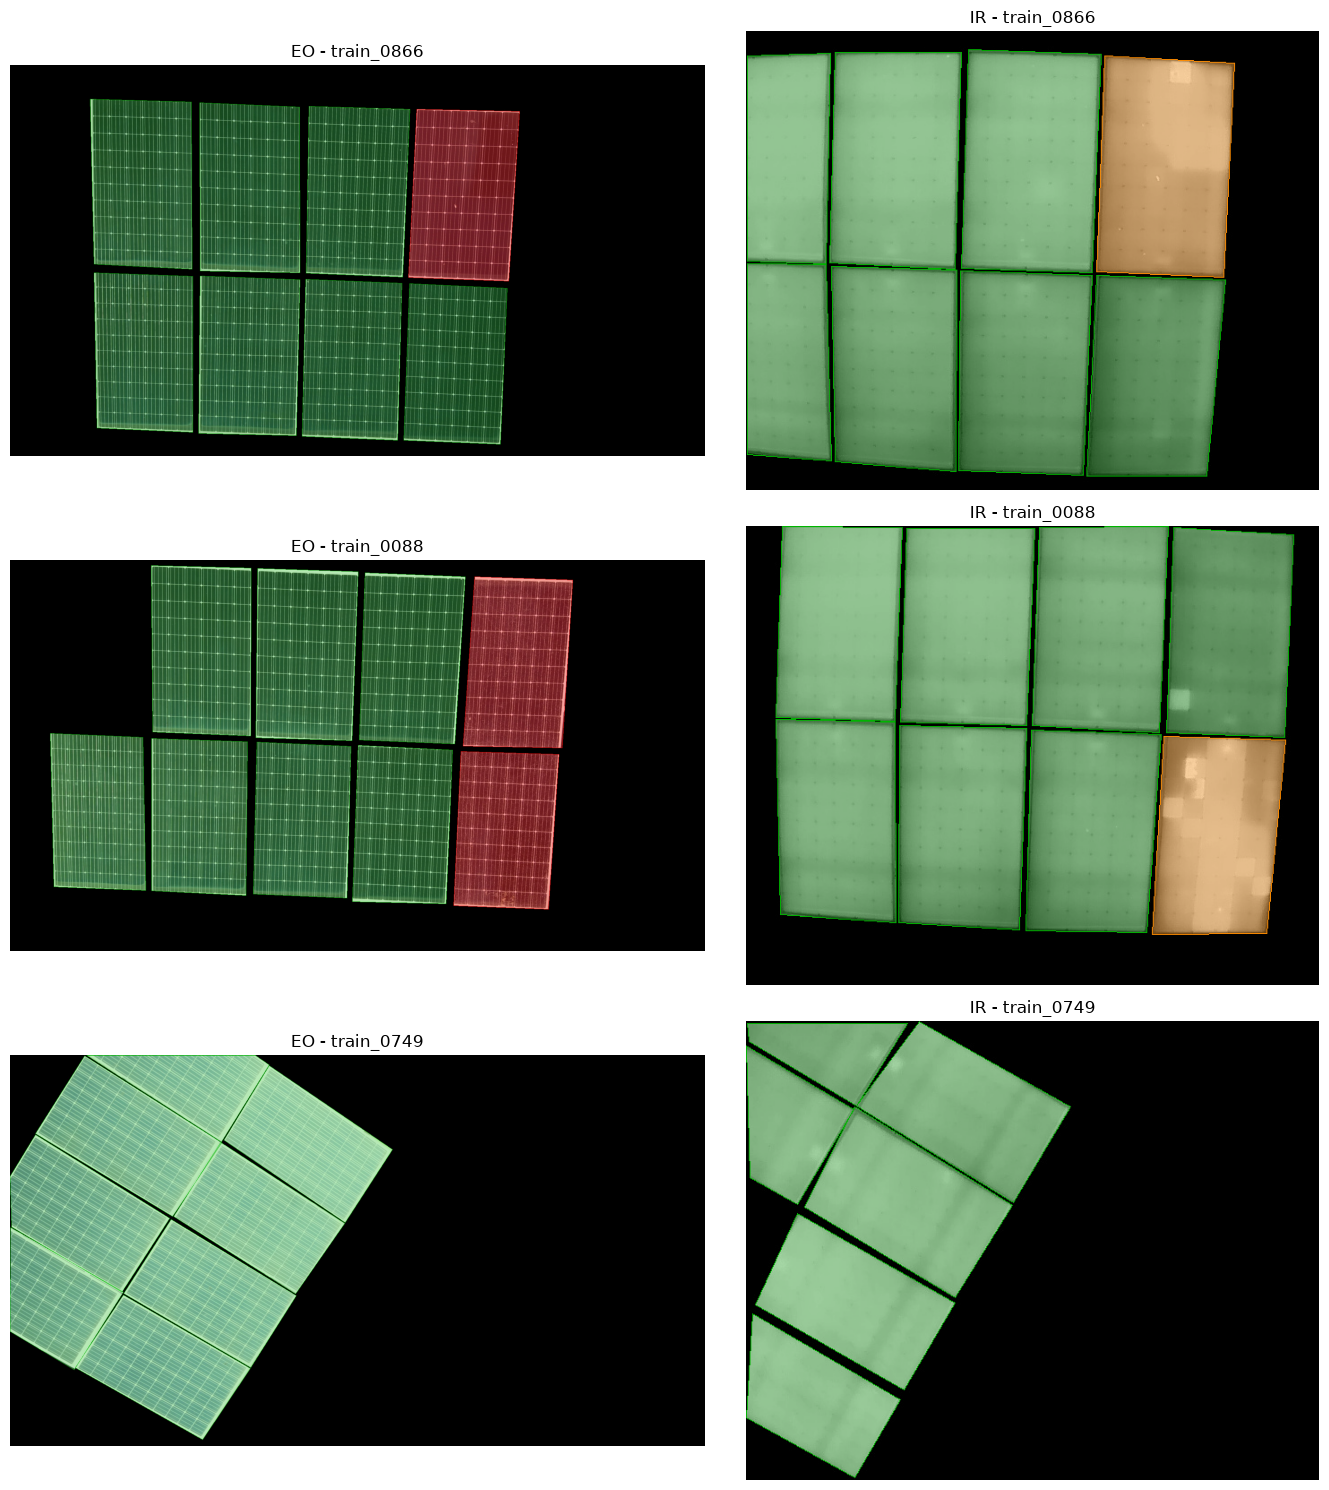

In [4]:

from pathlib import Path
import json
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Dataset paths
DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

TRAIN_ROOT = DATA_ROOT / "9_16_train_set" / "train"

EO_IMAGE = TRAIN_ROOT / "EO" / "image"
EO_LABEL = TRAIN_ROOT / "EO" / "label"

IR_IMAGE = TRAIN_ROOT / "IR" / "image"
IR_LABEL = TRAIN_ROOT / "IR" / "label"


def draw_annotations(image_path, json_path):
    image = Image.open(image_path).convert("RGB")

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    draw = ImageDraw.Draw(image, "RGBA")

    for shape in data.get("shapes", []):
        label = shape["label"]
        points = [tuple(p) for p in shape["points"]]

        if len(points) < 3:
            continue

        if label == "solar_panel":
            color = (0, 180, 0, 70)
            outline = (0, 180, 0, 255)
        elif label == "crack":
            color = (255, 0, 0, 90)
            outline = (255, 0, 0, 255)
        elif label == "hotspot":
            color = (255, 140, 0, 90)
            outline = (255, 140, 0, 255)
        else:
            color = (0, 100, 255, 70)
            outline = (0, 100, 255, 255)

        draw.polygon(points, fill=color, outline=outline)

    return image


# Randomly select 3 paired samples
sample_ids = random.sample(
    sorted(p.stem for p in EO_IMAGE.glob("*.jpg")),
    3
)

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for row, sample_id in enumerate(sample_ids):
    eo = draw_annotations(
        EO_IMAGE / f"{sample_id}.jpg",
        EO_LABEL / f"{sample_id}.json"
    )

    ir = draw_annotations(
        IR_IMAGE / f"{sample_id}.jpg",
        IR_LABEL / f"{sample_id}.json"
    )

    axes[row, 0].imshow(eo)
    axes[row, 0].set_title(f"EO - {sample_id}")
    axes[row, 1].imshow(ir)
    axes[row, 1].set_title(f"IR - {sample_id}")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [5]:
from pathlib import Path
import json

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

KIT_DIR = DATA_ROOT / "evaluation_kit" / "author-kit_1012"

files = [
    KIT_DIR / "README.md",
    KIT_DIR / "sample_submission.json",
    KIT_DIR / "make_submission.py"
]

for file in files:
    print("\n" + "=" * 80)
    print(f"FILE: {file.name}")
    print("=" * 80)

    if file.suffix == ".json":
        data = json.loads(file.read_text(encoding="utf-8"))
        print(json.dumps(data, ensure_ascii=False, indent=2)[:12000])
    else:
        print(file.read_text(encoding="utf-8")[:20000])


FILE: README.md
# AI CUP 2026 太陽能板瑕疵檢測與根因分析：官方評分說明（evaluation kit）

本文件說明提交格式、退件條件、定位分數與根因文字分數的計算方式。
各項敘述都以 AIdea 平台現行評分程式的實際行為為準。

## 這個資料夾裡有什麼（先讀這裡）

| 檔案 | 是什麼 | 怎麼用 |
|---|---|---|
| `README.md` | 本文件：提交格式與評分方式的完整說明 | 第一次使用請先看下方的「快速上手」，再讀第 3 節（提交格式）與第 4 節（標註慣例）；第 5～8 節說明怎麼算分 |
| `test_images.csv` | **測試影像的路徑清單**，不是影像本身，也不含任何答案。只有一欄 `filename`，共 1,392 筆（不含標題列；EO、IR 各 696 筆）。每筆是一張測試影像在資料集中的相對路徑，例如 `test/EO/image/test_001.jpg` | 提交檔的 key 必須和這裡的字串完全相同。`make_submission.py` 會讀這個檔來產生範本與檢查格式。放在 `make_submission.py` 旁邊即可，通常不需要自己開啟 |
| `make_submission.py` | 提交檔工具。只需要 Python 3，不需要安裝其他套件 | `python make_submission.py --template my_submission.json` 產生涵蓋全部測試影像的空白範本；送出前用 `python make_submission.py --check my_submission.json` 檢查格式（第 10 節） |
| `sample_submission.json` | 提交格式範例，示範各種寫法（多個物件、異常的 `reason`、2 點矩形、多邊形、空陣列） | 只用來看欄位怎麼寫。框刻意放在影像中沒有模組的位置，直接上傳的分數為 0，請不要當作預測結果提交 |

測試影像與訓練資料請使用先前發布的資料集。`train_groups.csv`（訓練影格分組）與資料集說明在另外提供的資料集補充檔中。

## 快速上手

第一次提交，照以下步驟做即可。每一步的細節見括號內的章節。

1. **準備工具**：把 `make_s

In [6]:
import json
from pathlib import Path
from collections import Counter

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

modalities = {
    "EO": DATA_ROOT / "9_16_train_set" / "train" / "EO" / "label",
    "IR": DATA_ROOT / "9_16_train_set" / "train" / "IR" / "label"
}

for modality, label_dir in modalities.items():

    print("\n" + "=" * 65)
    print(f"{modality} ANNOTATION ANALYSIS")
    print("=" * 65)

    label_counts = Counter()
    shape_types = Counter()
    reasons = Counter()
    reason_by_label = {}

    for json_file in sorted(label_dir.glob("*.json")):

        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)

        for shape in data.get("shapes", []):

            label = shape.get("label", "unknown")
            shape_type = shape.get("shape_type", "unknown")
            reason = shape.get("reason", "")

            label_counts[label] += 1
            shape_types[shape_type] += 1

            if isinstance(reason, str) and reason.strip():
                reasons[reason.strip()] += 1

                if label not in reason_by_label:
                    reason_by_label[label] = Counter()

                reason_by_label[label][reason.strip()] += 1

    print("\n[Shape Labels]")
    for label, count in label_counts.most_common():
        print(f"{label:20s}: {count}")

    print("\n[Shape Types]")
    for shape_type, count in shape_types.most_common():
        print(f"{shape_type:20s}: {count}")

    print("\n[Unique Root Cause Descriptions]")
    print("Total unique descriptions:", len(reasons))

    for reason, count in reasons.most_common(30):
        print(f"\nCount: {count}")
        print("Reason:", reason)

    print("\n[Root Cause by Label]")
    for label, counter in reason_by_label.items():
        print(f"\n{label}:")
        print("Unique reasons:", len(counter))
        for reason, count in counter.most_common(10):
            print(f"  {count} times | {reason}")


EO ANNOTATION ANALYSIS

[Shape Labels]
solar_panel         : 29553
crack               : 352

[Shape Types]
polygon             : 29905

[Unique Root Cause Descriptions]
Total unique descriptions: 49

Count: 19
Reason: 該片模組的板體破裂，損傷不僅止於表面。

Count: 19
Reason: 模組板結構破裂，電流路徑的完整性受到破壞。

Count: 16
Reason: 該模組板破損，裂縫波及內部導電結構。

Count: 15
Reason: 破裂貫穿模組板，導電結構同步受損。

Count: 14
Reason: 面板破裂明顯，損傷已及於內部導電層。

Count: 14
Reason: 該處模組板破裂，損傷範圍涵蓋導電路徑。

Count: 14
Reason: 面板本體已裂開，破損處的導電功能受損。

Count: 14
Reason: 模組板破裂，破損已延伸並影響導電路徑。

Count: 13
Reason: 模組板破裂，其導電路徑的完整性不再維持。

Count: 13
Reason: 該模組板有明顯裂損，影響電流正常通過。

Count: 13
Reason: 該模組面板破損，裂損深及導電層。

Count: 12
Reason: 面板出現裂損，導電路徑於該處受阻。

Count: 12
Reason: 該模組面板出現破裂，結構損傷波及內部導電結構。

Count: 12
Reason: 該模組板體受損破裂，影響其電流傳導。

Count: 12
Reason: 模組板破損，裂痕延伸並破壞導電連續性。

Count: 12
Reason: 該處面板結構破裂，導電層一併受損。

Count: 11
Reason: 模組板出現貫穿性破裂，內部導電結構受波及。

Count: 11
Reason: 面板破裂，導電路徑因結構受損而受到影響。

Count: 11
Reason: 面板本體破裂，該區導電能力已受損。

Count: 10
Reason: 模組板裂開，破損處無法維持正常導電。

Count: 10
Reason: 模組板已破

In [7]:

import json
from pathlib import Path
from collections import Counter

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

for modality, defect_label in [("EO", "crack"), ("IR", "hotspot")]:
    label_dir = DATA_ROOT / "9_16_train_set" / "train" / modality / "label"

    print(f"\n{'='*60}")
    print(f"{modality} - {defect_label}")
    print("="*60)

    samples = []

    for file in sorted(label_dir.glob("*.json")):
        data = json.loads(file.read_text(encoding="utf-8"))

        defects = [
            shape for shape in data.get("shapes", [])
            if shape.get("label") == defect_label
        ]

        if defects:
            samples.append((file.name, defects))

    print("Images containing defects:", len(samples))

    for filename, defects in samples[:3]:
        print(f"\nFile: {filename}")
        print("Defect polygons:", len(defects))

        for i, shape in enumerate(defects[:3]):
            print(f"  Polygon {i+1}")
            print("  Reason:", shape.get("reason"))
            print("  Description:", shape.get("description"))



EO - crack
Images containing defects: 258

File: train_0001.json
Defect polygons: 1
  Polygon 1
  Reason: 面板出現裂損，導電路徑於該處受阻。
  Description: 

File: train_0004.json
Defect polygons: 2
  Polygon 1
  Reason: 模組板裂開，破損處無法維持正常導電。
  Description: 
  Polygon 2
  Reason: 模組板裂開，破損處無法維持正常導電。
  Description: 

File: train_0007.json
Defect polygons: 1
  Polygon 1
  Reason: 模組表面出現明顯裂紋，推測為外部物理衝擊所造成。
  Description: 

IR - hotspot
Images containing defects: 428

File: train_0001.json
Defect polygons: 1
  Polygon 1
  Reason: 模組板破裂造成電流分布不均，局部電阻上升並形成異常發熱區。
  Description: 

File: train_0004.json
Defect polygons: 1
  Polygon 1
  Reason: 該熱點位置與模組板破裂區域重合，推測為導電路徑受損所致。
  Description: 

File: train_0005.json
Defect polygons: 1
  Polygon 1
  Reason: 可能為內部隱裂、接觸電阻上升或電性異常，進而引發局部過熱。
  Description: 


In [8]:

import json
from pathlib import Path
from collections import Counter

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

for modality, defect_label in [
    ("EO", "crack"),
    ("IR", "hotspot")
]:
    label_dir = (
        DATA_ROOT / "9_16_train_set" /
        "train" / modality / "label"
    )

    print(f"\n{'='*60}")
    print(f"{modality} - Multiple Defect Analysis")
    print("="*60)

    image_defect_counts = Counter()
    same_reason_images = 0
    different_reason_images = 0
    empty_reason_instances = 0

    for file in sorted(label_dir.glob("*.json")):
        data = json.loads(file.read_text(encoding="utf-8"))

        defects = [
            shape for shape in data.get("shapes", [])
            if shape.get("label") == defect_label
        ]

        if not defects:
            continue

        image_defect_counts[len(defects)] += 1

        reasons = [
            shape.get("reason", "").strip()
            for shape in defects
        ]

        empty_reason_instances += sum(not r for r in reasons)

        unique_reasons = set(r for r in reasons if r)

        if len(defects) > 1:
            if len(unique_reasons) <= 1:
                same_reason_images += 1
            else:
                different_reason_images += 1

    print("\n[Defects per image]")
    for count, images in sorted(image_defect_counts.items()):
        print(f"{count} defect(s): {images} images")

    print("\n[Reason consistency]")
    print("Multiple defects with same reason:",
          same_reason_images)
    print("Multiple defects with different reasons:",
          different_reason_images)
    print("Empty reason instances:",
          empty_reason_instances)



EO - Multiple Defect Analysis

[Defects per image]
1 defect(s): 164 images
2 defect(s): 94 images

[Reason consistency]
Multiple defects with same reason: 1
Multiple defects with different reasons: 93
Empty reason instances: 0

IR - Multiple Defect Analysis

[Defects per image]
1 defect(s): 412 images
2 defect(s): 16 images

[Reason consistency]
Multiple defects with same reason: 0
Multiple defects with different reasons: 16
Empty reason instances: 0


In [9]:

import pandas as pd
import json
from pathlib import Path
from PIL import Image
from collections import defaultdict

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

# 1. Read capture group information
group_file = (
    DATA_ROOT /
    "SolarDefectDataset_supplement" /
    "train_groups.csv"
)

groups = pd.read_csv(group_file)

print("=== train_groups.csv ===")
print("Columns:", groups.columns.tolist())
print("Rows:", len(groups))
display(groups.head())

# 2. Inspect image dimensions
for modality in ["EO", "IR"]:
    image_dir = (
        DATA_ROOT / "9_16_train_set" /
        "train" / modality / "image"
    )

    dimensions = defaultdict(int)

    for image_path in image_dir.glob("*"):
        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1
        except Exception:
            pass

    print(f"\n=== {modality} Image Dimensions ===")
    for size, count in sorted(
        dimensions.items(),
        key=lambda x: x[1],
        reverse=True
    ):
        print(f"{size}: {count} images")

# 3. Inspect group distribution
print("\n=== Group Distribution ===")

# Try to identify the group column
group_columns = [
    c for c in groups.columns
    if "group" in c.lower()
]

if group_columns:
    group_col = group_columns[0]
    print(groups[group_col].value_counts().sort_index())
else:
    print("Could not automatically identify group column.")
    print("Please inspect the CSV columns above.")


=== train_groups.csv ===
Columns: ['frame_id', 'group']
Rows: 1046


,frame_id,group
0,train_0001,G04
1,train_0002,G04
2,train_0003,G01
3,train_0004,G04
4,train_0005,G02



=== EO Image Dimensions ===
(1920, 1080): 1046 images

=== IR Image Dimensions ===
(640, 512): 1046 images

=== Group Distribution ===
group
G01    288
G02    197
G03     23
G04    305
G05     11
G06      4
G07     58
G08      7
G09     18
G10     72
G11     40
G12     23
Name: count, dtype: int64


In [10]:

import pandas as pd
import json
from pathlib import Path
from collections import defaultdict

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

# Load group mapping
groups = pd.read_csv(
    DATA_ROOT / "SolarDefectDataset_supplement" / "train_groups.csv"
)

# Initialize statistics
stats = defaultdict(lambda: {
    "images": 0,
    "EO_crack_images": 0,
    "EO_crack_instances": 0,
    "IR_hotspot_images": 0,
    "IR_hotspot_instances": 0,
    "normal_images": 0
})

for _, row in groups.iterrows():

    frame_id = row["frame_id"]
    group = row["group"]

    stats[group]["images"] += 1

    eo_file = (
        DATA_ROOT / "9_16_train_set" /
        "train" / "EO" / "label" /
        f"{frame_id}.json"
    )

    ir_file = (
        DATA_ROOT / "9_16_train_set" /
        "train" / "IR" / "label" /
        f"{frame_id}.json"
    )

    eo_data = json.loads(eo_file.read_text(encoding="utf-8"))
    ir_data = json.loads(ir_file.read_text(encoding="utf-8"))

    eo_cracks = [
        s for s in eo_data["shapes"]
        if s["label"] == "crack"
    ]

    ir_hotspots = [
        s for s in ir_data["shapes"]
        if s["label"] == "hotspot"
    ]

    if eo_cracks:
        stats[group]["EO_crack_images"] += 1

    stats[group]["EO_crack_instances"] += len(eo_cracks)

    if ir_hotspots:
        stats[group]["IR_hotspot_images"] += 1

    stats[group]["IR_hotspot_instances"] += len(ir_hotspots)

    if not eo_cracks and not ir_hotspots:
        stats[group]["normal_images"] += 1

# Display results
result = pd.DataFrame.from_dict(stats, orient="index")
result.index.name = "group"

result = result.sort_index()

display(result)

print("\n=== Total ===")
display(result.sum().to_frame("Total"))


,images,EO_crack_images,EO_crack_instances,IR_hotspot_images,IR_hotspot_instances,normal_images
group,,,,,,
G01,288,34,34,7,7,247
G02,197,0,0,190,190,7
G03,23,0,0,16,31,7
G04,305,216,310,215,216,88
G05,11,0,0,0,0,11
G06,4,0,0,0,0,4
G07,58,8,8,0,0,50
G08,7,0,0,0,0,7
G09,18,0,0,0,0,18



=== Total ===


,Total
images,1046
EO_crack_images,258
EO_crack_instances,352
IR_hotspot_images,428
IR_hotspot_instances,444
normal_images,574


In [12]:

import pandas as pd
from pathlib import Path

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

groups = pd.read_csv(
    DATA_ROOT / "SolarDefectDataset_supplement" /
    "train_groups.csv"
)

# EO: hold out G01
groups["EO_split"] = groups["group"].apply(
    lambda g: "val" if g == "G01" else "train"
)

# IR: hold out G04
groups["IR_split"] = groups["group"].apply(
    lambda g: "val" if g == "G04" else "train"
)

output_file = DATA_ROOT / "outputs" / "train_val_split.csv"

groups.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Updated:", output_file)

for modality in ["EO", "IR"]:
    split_col = f"{modality}_split"

    print(f"\n=== {modality} ===")

    print(
        groups.groupby(split_col)
        .agg(
            images=("frame_id", "count"),
            groups=("group", "nunique")
        )
    )

    print("\nGroup leakage check:")
    print(pd.crosstab(groups["group"], groups[split_col]))


Updated: C:\Users\Sharon\Downloads\VLPaicup\outputs\train_val_split.csv

=== EO ===
          images  groups
EO_split                
train        758      11
val          288       1

Group leakage check:
EO_split  train  val
group               
G01           0  288
G02         197    0
G03          23    0
G04         305    0
G05          11    0
G06           4    0
G07          58    0
G08           7    0
G09          18    0
G10          72    0
G11          40    0
G12          23    0

=== IR ===
          images  groups
IR_split                
train        741      11
val          305       1

Group leakage check:
IR_split  train  val
group               
G01         288    0
G02         197    0
G03          23    0
G04           0  305
G05          11    0
G06           4    0
G07          58    0
G08           7    0
G09          18    0
G10          72    0
G11          40    0
G12          23    0


In [13]:

import json
import shutil
import math
import pandas as pd

from pathlib import Path
from collections import Counter

# ==========================================
# 1. Configuration
# ==========================================

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

TRAIN_ROOT = DATA_ROOT / "9_16_train_set" / "train"
OUTPUT_ROOT = DATA_ROOT / "outputs"

SPLIT_FILE = OUTPUT_ROOT / "train_val_split.csv"

# Separate class mapping for each modality
CONFIGS = {
    "EO": {
        "defect": "crack",
        "classes": {
            "solar_panel": 0,
            "crack": 1
        },
        "split_column": "EO_split"
    },
    "IR": {
        "defect": "hotspot",
        "classes": {
            "solar_panel": 0,
            "hotspot": 1
        },
        "split_column": "IR_split"
    }
}

IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

# ==========================================
# 2. Load split configuration
# ==========================================

split_df = pd.read_csv(SPLIT_FILE)

print("Loaded split file:", SPLIT_FILE)
print("Total frames:", len(split_df))


# ==========================================
# 3. Polygon conversion function
# ==========================================

def convert_polygon(shape, image_width, image_height):

    points = shape.get("points", [])

    if len(points) < 3:
        raise ValueError("Polygon has fewer than 3 points.")

    normalized = []

    for point in points:

        x, y = float(point[0]), float(point[1])

        if not math.isfinite(x) or not math.isfinite(y):
            raise ValueError("Polygon contains invalid coordinates.")

        # Allow tiny coordinate errors, but reject larger ones
        if x < -1 or x > image_width + 1:
            raise ValueError(f"X coordinate out of bounds: {x}")

        if y < -1 or y > image_height + 1:
            raise ValueError(f"Y coordinate out of bounds: {y}")

        # Clip tiny boundary errors
        x = min(max(x, 0), image_width)
        y = min(max(y, 0), image_height)

        normalized.extend([
            x / image_width,
            y / image_height
        ])

    # Remove duplicated closing point if present
    if (
        len(normalized) >= 6
        and normalized[0] == normalized[-2]
        and normalized[1] == normalized[-1]
    ):
        normalized = normalized[:-2]

    if len(normalized) < 6:
        raise ValueError("Polygon has fewer than 3 unique points.")

    return normalized


# ==========================================
# 4. Find corresponding source image
# ==========================================

def find_image(image_dir, frame_id):

    for ext in IMAGE_EXTENSIONS:

        candidate = image_dir / f"{frame_id}{ext}"

        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Cannot find image for {frame_id} in {image_dir}"
    )


# ==========================================
# 5. Build EO / IR datasets
# ==========================================

for modality, config in CONFIGS.items():

    print("\n" + "=" * 65)
    print(f"BUILDING {modality} YOLO SEGMENTATION DATASET")
    print("=" * 65)

    source_image_dir = TRAIN_ROOT / modality / "image"
    source_label_dir = TRAIN_ROOT / modality / "label"

    dataset_dir = OUTPUT_ROOT / f"yolo_{modality.lower()}"

    # Recreate generated image/label directories
    for subdir in [
        dataset_dir / "images",
        dataset_dir / "labels"
    ]:
        if subdir.exists():
            shutil.rmtree(subdir)

    for split in ["train", "val"]:
        (dataset_dir / "images" / split).mkdir(
            parents=True, exist_ok=True
        )
        (dataset_dir / "labels" / split).mkdir(
            parents=True, exist_ok=True
        )

    class_mapping = config["classes"]
    split_column = config["split_column"]

    statistics = {
        "train": Counter(),
        "val": Counter()
    }

    total_images = Counter()
    errors = []

    # --------------------------------------
    # Process every frame
    # --------------------------------------

    for _, row in split_df.iterrows():

        frame_id = row["frame_id"]
        split = row[split_column]

        image_path = find_image(
            source_image_dir,
            frame_id
        )

        json_path = source_label_dir / f"{frame_id}.json"

        if not json_path.exists():
            errors.append(f"Missing JSON: {json_path}")
            continue

        try:

            data = json.loads(
                json_path.read_text(encoding="utf-8")
            )

            image_width = data["imageWidth"]
            image_height = data["imageHeight"]

            # Check image dimensions against JSON
            from PIL import Image

            with Image.open(image_path) as img:
                actual_width, actual_height = img.size

            if (
                actual_width != image_width
                or actual_height != image_height
            ):
                raise ValueError(
                    f"Image dimension mismatch: {frame_id}"
                )

            yolo_lines = []

            for shape in data.get("shapes", []):

                label = shape.get("label")

                if label not in class_mapping:
                    raise ValueError(
                        f"Unknown label '{label}' in {frame_id}"
                    )

                if shape.get("shape_type") != "polygon":
                    raise ValueError(
                        f"Unsupported shape type in {frame_id}"
                    )

                class_id = class_mapping[label]

                coordinates = convert_polygon(
                    shape,
                    image_width,
                    image_height
                )

                line = (
                    str(class_id)
                    + " "
                    + " ".join(
                        f"{v:.6f}" for v in coordinates
                    )
                )

                yolo_lines.append(line)

                statistics[split][label] += 1

            # Copy original image
            target_image = (
                dataset_dir / "images" /
                split / image_path.name
            )

            shutil.copy2(image_path, target_image)

            # Save YOLO label file
            target_label = (
                dataset_dir / "labels" /
                split / f"{frame_id}.txt"
            )

            # Empty file is valid for images with no objects
            target_label.write_text(
                "\n".join(yolo_lines),
                encoding="utf-8"
            )

            total_images[split] += 1

        except Exception as e:
            errors.append(f"{frame_id}: {e}")

    # --------------------------------------
    # Generate data.yaml
    # --------------------------------------

    yaml_lines = [
        f"path: '{dataset_dir.as_posix()}'",
        "train: images/train",
        "val: images/val",
        "",
        "names:"
    ]

    for label, class_id in class_mapping.items():
        yaml_lines.append(
            f"  {class_id}: {label}"
        )

    yaml_path = dataset_dir / "data.yaml"

    yaml_path.write_text(
        "\n".join(yaml_lines) + "\n",
        encoding="utf-8"
    )

    # --------------------------------------
    # Report
    # --------------------------------------

    print("\n[Image Statistics]")
    print("Train:", total_images["train"])
    print("Validation:", total_images["val"])

    print("\n[Instance Statistics]")

    for split in ["train", "val"]:
        print(f"\n{split.upper()}")

        for label in class_mapping:
            print(
                f"{label:15s}: "
                f"{statistics[split][label]}"
            )

    print("\n[Errors]")
    print("Total errors:", len(errors))

    for error in errors[:10]:
        print(error)

    if errors:
        print(
            "\nWARNING: Dataset has errors. "
            "Do not start training yet."
        )

    print("\nDataset saved:", dataset_dir)
    print("YAML saved:", yaml_path)

print("\n" + "=" * 65)
print("DATASET CONVERSION FINISHED")
print("=" * 65)


Loaded split file: C:\Users\Sharon\Downloads\VLPaicup\outputs\train_val_split.csv
Total frames: 1046

BUILDING EO YOLO SEGMENTATION DATASET

[Image Statistics]
Train: 758
Validation: 288

[Instance Statistics]

TRAIN
solar_panel    : 27216
crack          : 318

VAL
solar_panel    : 2337
crack          : 34

[Errors]
Total errors: 0

Dataset saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo
YAML saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo\data.yaml

BUILDING IR YOLO SEGMENTATION DATASET

[Image Statistics]
Train: 741
Validation: 305

[Instance Statistics]

TRAIN
solar_panel    : 23892
hotspot        : 228

VAL
solar_panel    : 2365
hotspot        : 216

[Errors]
Total errors: 0

Dataset saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_ir
YAML saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_ir\data.yaml

DATASET CONVERSION FINISHED


In [14]:

import json
import shutil
import math
import pandas as pd

from pathlib import Path
from collections import Counter

# ==========================================
# 1. Configuration
# ==========================================

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

TRAIN_ROOT = DATA_ROOT / "9_16_train_set" / "train"
OUTPUT_ROOT = DATA_ROOT / "outputs"

SPLIT_FILE = OUTPUT_ROOT / "train_val_split.csv"

# Separate class mapping for each modality
CONFIGS = {
    "EO": {
        "defect": "crack",
        "classes": {
            "solar_panel": 0,
            "crack": 1
        },
        "split_column": "EO_split"
    },
    "IR": {
        "defect": "hotspot",
        "classes": {
            "solar_panel": 0,
            "hotspot": 1
        },
        "split_column": "IR_split"
    }
}

IMAGE_EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

# ==========================================
# 2. Load split configuration
# ==========================================

split_df = pd.read_csv(SPLIT_FILE)

print("Loaded split file:", SPLIT_FILE)
print("Total frames:", len(split_df))


# ==========================================
# 3. Polygon conversion function
# ==========================================

def convert_polygon(shape, image_width, image_height):

    points = shape.get("points", [])

    if len(points) < 3:
        raise ValueError("Polygon has fewer than 3 points.")

    normalized = []

    for point in points:

        x, y = float(point[0]), float(point[1])

        if not math.isfinite(x) or not math.isfinite(y):
            raise ValueError("Polygon contains invalid coordinates.")

        # Allow tiny coordinate errors, but reject larger ones
        if x < -1 or x > image_width + 1:
            raise ValueError(f"X coordinate out of bounds: {x}")

        if y < -1 or y > image_height + 1:
            raise ValueError(f"Y coordinate out of bounds: {y}")

        # Clip tiny boundary errors
        x = min(max(x, 0), image_width)
        y = min(max(y, 0), image_height)

        normalized.extend([
            x / image_width,
            y / image_height
        ])

    # Remove duplicated closing point if present
    if (
        len(normalized) >= 6
        and normalized[0] == normalized[-2]
        and normalized[1] == normalized[-1]
    ):
        normalized = normalized[:-2]

    if len(normalized) < 6:
        raise ValueError("Polygon has fewer than 3 unique points.")

    return normalized


# ==========================================
# 4. Find corresponding source image
# ==========================================

def find_image(image_dir, frame_id):

    for ext in IMAGE_EXTENSIONS:

        candidate = image_dir / f"{frame_id}{ext}"

        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Cannot find image for {frame_id} in {image_dir}"
    )


# ==========================================
# 5. Build EO / IR datasets
# ==========================================

for modality, config in CONFIGS.items():

    print("\n" + "=" * 65)
    print(f"BUILDING {modality} YOLO SEGMENTATION DATASET")
    print("=" * 65)

    source_image_dir = TRAIN_ROOT / modality / "image"
    source_label_dir = TRAIN_ROOT / modality / "label"

    dataset_dir = OUTPUT_ROOT / f"yolo_{modality.lower()}"

    # Recreate generated image/label directories
    for subdir in [
        dataset_dir / "images",
        dataset_dir / "labels"
    ]:
        if subdir.exists():
            shutil.rmtree(subdir)

    for split in ["train", "val"]:
        (dataset_dir / "images" / split).mkdir(
            parents=True, exist_ok=True
        )
        (dataset_dir / "labels" / split).mkdir(
            parents=True, exist_ok=True
        )

    class_mapping = config["classes"]
    split_column = config["split_column"]

    statistics = {
        "train": Counter(),
        "val": Counter()
    }

    total_images = Counter()
    errors = []

    # --------------------------------------
    # Process every frame
    # --------------------------------------

    for _, row in split_df.iterrows():

        frame_id = row["frame_id"]
        split = row[split_column]

        image_path = find_image(
            source_image_dir,
            frame_id
        )

        json_path = source_label_dir / f"{frame_id}.json"

        if not json_path.exists():
            errors.append(f"Missing JSON: {json_path}")
            continue

        try:

            data = json.loads(
                json_path.read_text(encoding="utf-8")
            )

            image_width = data["imageWidth"]
            image_height = data["imageHeight"]

            # Check image dimensions against JSON
            from PIL import Image

            with Image.open(image_path) as img:
                actual_width, actual_height = img.size

            if (
                actual_width != image_width
                or actual_height != image_height
            ):
                raise ValueError(
                    f"Image dimension mismatch: {frame_id}"
                )

            yolo_lines = []

            for shape in data.get("shapes", []):

                label = shape.get("label")

                if label not in class_mapping:
                    raise ValueError(
                        f"Unknown label '{label}' in {frame_id}"
                    )

                if shape.get("shape_type") != "polygon":
                    raise ValueError(
                        f"Unsupported shape type in {frame_id}"
                    )

                class_id = class_mapping[label]

                coordinates = convert_polygon(
                    shape,
                    image_width,
                    image_height
                )

                line = (
                    str(class_id)
                    + " "
                    + " ".join(
                        f"{v:.6f}" for v in coordinates
                    )
                )

                yolo_lines.append(line)

                statistics[split][label] += 1

            # Copy original image
            target_image = (
                dataset_dir / "images" /
                split / image_path.name
            )

            shutil.copy2(image_path, target_image)

            # Save YOLO label file
            target_label = (
                dataset_dir / "labels" /
                split / f"{frame_id}.txt"
            )

            # Empty file is valid for images with no objects
            target_label.write_text(
                "\n".join(yolo_lines),
                encoding="utf-8"
            )

            total_images[split] += 1

        except Exception as e:
            errors.append(f"{frame_id}: {e}")

    # --------------------------------------
    # Generate data.yaml
    # --------------------------------------

    yaml_lines = [
        f"path: '{dataset_dir.as_posix()}'",
        "train: images/train",
        "val: images/val",
        "",
        "names:"
    ]

    for label, class_id in class_mapping.items():
        yaml_lines.append(
            f"  {class_id}: {label}"
        )

    yaml_path = dataset_dir / "data.yaml"

    yaml_path.write_text(
        "\n".join(yaml_lines) + "\n",
        encoding="utf-8"
    )

    # --------------------------------------
    # Report
    # --------------------------------------

    print("\n[Image Statistics]")
    print("Train:", total_images["train"])
    print("Validation:", total_images["val"])

    print("\n[Instance Statistics]")

    for split in ["train", "val"]:
        print(f"\n{split.upper()}")

        for label in class_mapping:
            print(
                f"{label:15s}: "
                f"{statistics[split][label]}"
            )

    print("\n[Errors]")
    print("Total errors:", len(errors))

    for error in errors[:10]:
        print(error)

    if errors:
        print(
            "\nWARNING: Dataset has errors. "
            "Do not start training yet."
        )

    print("\nDataset saved:", dataset_dir)
    print("YAML saved:", yaml_path)

print("\n" + "=" * 65)
print("DATASET CONVERSION FINISHED")
print("=" * 65)


Loaded split file: C:\Users\Sharon\Downloads\VLPaicup\outputs\train_val_split.csv
Total frames: 1046

BUILDING EO YOLO SEGMENTATION DATASET

[Image Statistics]
Train: 758
Validation: 288

[Instance Statistics]

TRAIN
solar_panel    : 27216
crack          : 318

VAL
solar_panel    : 2337
crack          : 34

[Errors]
Total errors: 0

Dataset saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo
YAML saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo\data.yaml

BUILDING IR YOLO SEGMENTATION DATASET

[Image Statistics]
Train: 741
Validation: 305

[Instance Statistics]

TRAIN
solar_panel    : 23892
hotspot        : 228

VAL
solar_panel    : 2365
hotspot        : 216

[Errors]
Total errors: 0

Dataset saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_ir
YAML saved: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_ir\data.yaml

DATASET CONVERSION FINISHED


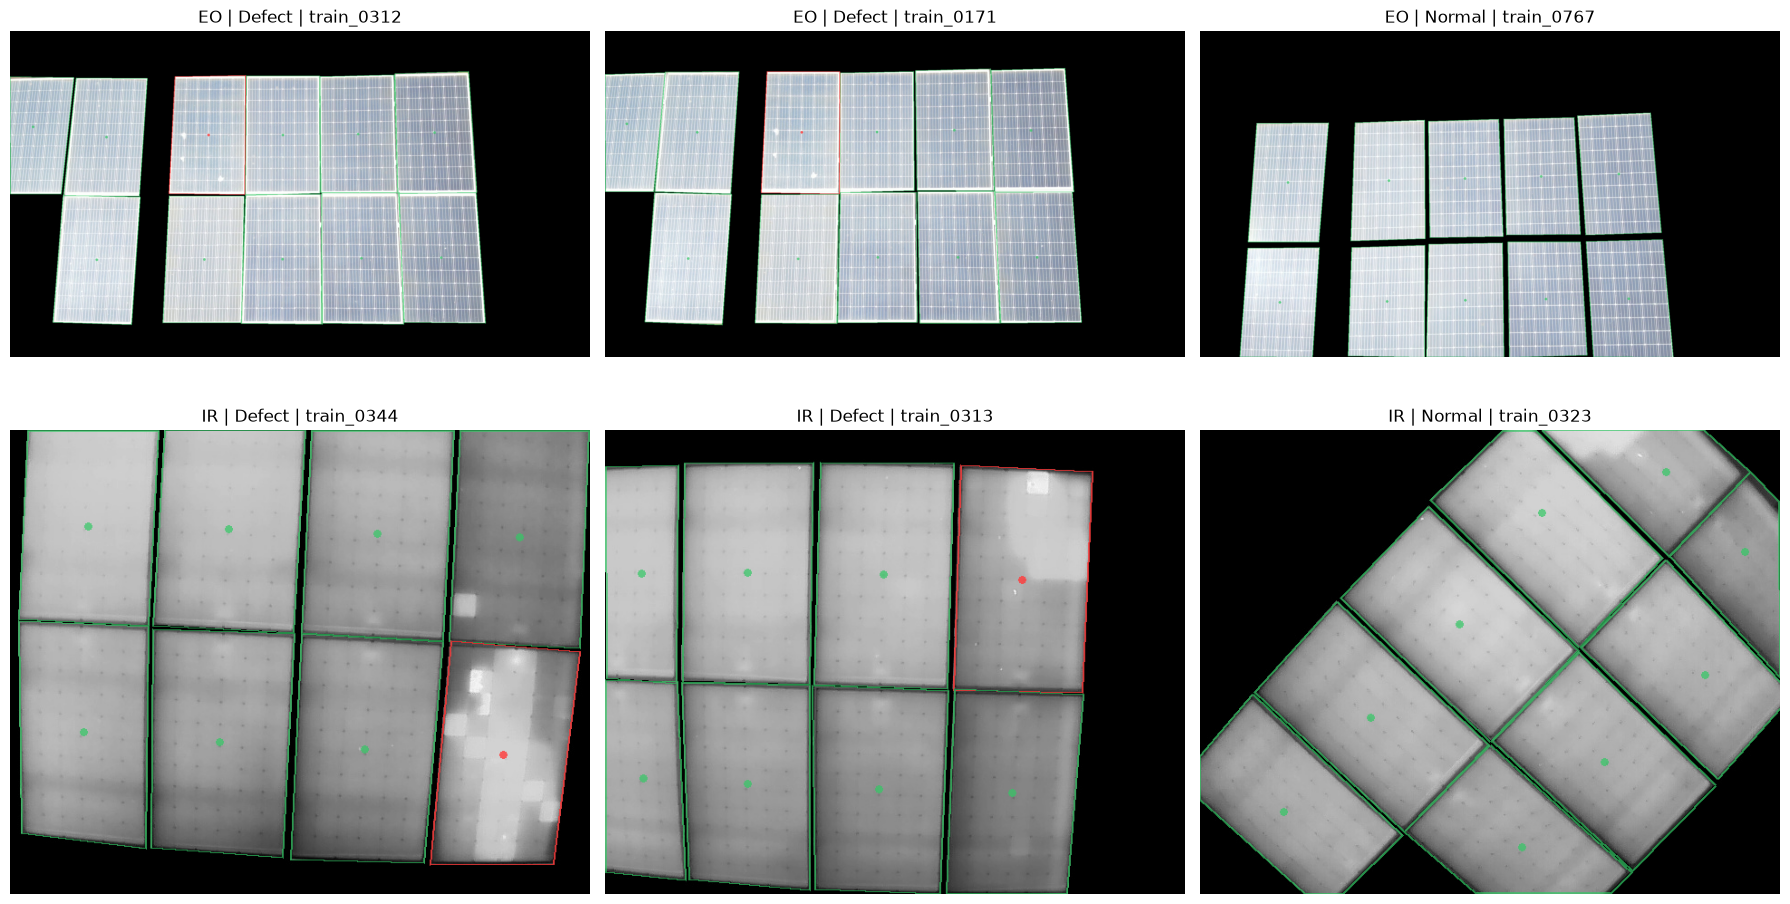

In [15]:

import random
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
OUTPUT_ROOT = DATA_ROOT / "outputs"

random.seed(42)

CONFIGS = {
    "EO": {
        "defect": "crack",
        "classes": {
            0: "solar_panel",
            1: "crack"
        }
    },
    "IR": {
        "defect": "hotspot",
        "classes": {
            0: "solar_panel",
            1: "hotspot"
        }
    }
}

def visualize_yolo_sample(modality, image_path):

    dataset_dir = OUTPUT_ROOT / f"yolo_{modality.lower()}"

    label_path = (
        dataset_dir / "labels" / "val" /
        f"{image_path.stem}.txt"
    )

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    overlay = Image.new("RGBA", image.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)

    config = CONFIGS[modality]

    if label_path.exists():

        lines = label_path.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        for line in lines:

            if not line.strip():
                continue

            values = list(map(float, line.split()))

            class_id = int(values[0])
            coords = values[1:]

            points = [
                (
                    round(coords[i] * width),
                    round(coords[i + 1] * height)
                )
                for i in range(0, len(coords), 2)
            ]

            if class_id == 0:
                color = (50, 200, 100, 180)
            else:
                color = (255, 60, 60, 210)

            # Draw polygon outline
            draw.line(
                points + [points[0]],
                fill=color,
                width=max(2, width // 500)
            )

            # Mark polygon center
            center_x = sum(p[0] for p in points) / len(points)
            center_y = sum(p[1] for p in points) / len(points)

            draw.ellipse(
                (
                    center_x - 4, center_y - 4,
                    center_x + 4, center_y + 4
                ),
                fill=color
            )

    result = Image.alpha_composite(
        image.convert("RGBA"),
        overlay
    )

    return result.convert("RGB")


# Show 2 defect images + 1 normal image per modality
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for row, modality in enumerate(["EO", "IR"]):

    dataset_dir = OUTPUT_ROOT / f"yolo_{modality.lower()}"

    image_dir = dataset_dir / "images" / "val"
    label_dir = dataset_dir / "labels" / "val"

    defect_files = []
    normal_files = []

    for label_file in label_dir.glob("*.txt"):

        lines = label_file.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        class_ids = [
            int(line.split()[0])
            for line in lines
            if line.strip()
        ]

        if 1 in class_ids:
            defect_files.append(label_file.stem)

        elif 0 in class_ids:
            normal_files.append(label_file.stem)

    selected = (
        random.sample(defect_files, min(2, len(defect_files)))
        + random.sample(normal_files, min(1, len(normal_files)))
    )

    for col, frame_id in enumerate(selected):

        image_path = next(
            image_dir.glob(frame_id + ".*")
        )

        result = visualize_yolo_sample(
            modality,
            image_path
        )

        axes[row, col].imshow(result)
        axes[row, col].axis("off")

        category = (
            "Defect" if frame_id in defect_files
            else "Normal"
        )

        axes[row, col].set_title(
            f"{modality} | {category} | {frame_id}"
        )

plt.tight_layout()
plt.show()


In [1]:
import torch
import numpy as np
import ultralytics

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Ultralytics:", ultralytics.__version__)
print("XPU:", torch.xpu.is_available())
print("GPU:", torch.xpu.get_device_name(0))

x = torch.rand(1000, 1000, device="xpu")
y = x @ x
torch.xpu.synchronize()

print("Matrix multiplication: SUCCESS")

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Sharon\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.14.1+xpu
NumPy: 2.5.5
Ultralytics: 8.4.215
XPU: True
GPU: Intel(R) Arc(TM) 130T GPU (16GB)
Matrix multiplication: SUCCESS


In [2]:
from pathlib import Path
import yaml
import torch

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
OUTPUT_DIR = DATA_ROOT / "outputs"

for modality in ["eo", "ir"]:
    yaml_path = OUTPUT_DIR / f"yolo_{modality}" / "data.yaml"

    with open(yaml_path, encoding="utf-8") as f:
        config = yaml.safe_load(f)

    print(f"\n{modality.upper()} dataset")
    print("Names:", config["names"])
    print("Train:", config["train"])
    print("Val:", config["val"])
    print("YAML:", yaml_path.exists())

print("\nGPU:", torch.xpu.get_device_name(0))


EO dataset
Names: {0: 'solar_panel', 1: 'crack'}
Train: images/train
Val: images/val
YAML: True

IR dataset
Names: {0: 'solar_panel', 1: 'hotspot'}
Train: images/train
Val: images/val
YAML: True

GPU: Intel(R) Arc(TM) 130T GPU (16GB)


In [3]:
from pathlib import Path
import torch
from ultralytics import YOLO

# Dataset path
DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
EO_YAML = DATA_ROOT / "outputs" / "yolo_eo" / "data.yaml"

assert EO_YAML.exists(), f"Dataset YAML not found: {EO_YAML}"

# Confirm GPU
assert torch.xpu.is_available(), "Intel XPU is unavailable"

print("GPU:", torch.xpu.get_device_name(0))
print("Dataset:", EO_YAML)

# Load lightweight segmentation model
model = YOLO("yolo11n-seg.pt")

# Smoke test
results = model.train(
    data=str(EO_YAML),
    epochs=1,
    imgsz=320,
    batch=1,
    fraction=0.02,
    workers=0,
    device="xpu:0",
    amp=False,
    cache=False,
    plots=False,
    project=str(DATA_ROOT / "outputs" / "runs"),
    name="eo_xpu_smoke",
    exist_ok=True,
    verbose=True
)

print("\nEO smoke test completed!")

GPU: Intel(R) Arc(TM) 130T GPU (16GB)
Dataset: C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo\data.yaml
Ultralytics 8.4.215  Python-3.14.10 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) 130T GPU (16GB))
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo\data.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.02, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=30

In [4]:

from pathlib import Path
import torch
from ultralytics import YOLO

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
EO_YAML = DATA_ROOT / "outputs" / "yolo_eo" / "data.yaml"

assert torch.xpu.is_available(), "XPU unavailable"
assert EO_YAML.exists(), "EO dataset not found"

model = YOLO("yolo11n-seg.pt")

eo_results = model.train(
    data=str(EO_YAML),
    epochs=3,
    imgsz=320,
    batch=1,
    fraction=1.0,
    workers=0,
    device="xpu:0",
    amp=False,
    cache=False,
    val=False,
    plots=False,
    save=True,
    project=str(DATA_ROOT / "outputs" / "runs"),
    name="eo_baseline",
    exist_ok=True,
    verbose=True
)

print("EO baseline training completed!")


Ultralytics 8.4.215  Python-3.14.10 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) 130T GPU (16GB))
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_eo\data.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=eo_baseline

In [5]:

IR_YAML = DATA_ROOT / "outputs" / "yolo_ir" / "data.yaml"

assert IR_YAML.exists(), "IR dataset not found"

model_ir = YOLO("yolo11n-seg.pt")

ir_results = model_ir.train(
    data=str(IR_YAML),
    epochs=3,
    imgsz=320,
    batch=1,
    fraction=1.0,
    workers=0,
    device="xpu:0",
    amp=False,
    cache=False,
    val=False,
    plots=False,
    save=True,
    project=str(DATA_ROOT / "outputs" / "runs"),
    name="ir_baseline",
    exist_ok=True,
    verbose=True
)

print("IR baseline training completed!")


Ultralytics 8.4.215  Python-3.14.10 torch-2.14.1+xpu XPU:0 (Intel(R) Arc(TM) 130T GPU (16GB))
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Sharon\Downloads\VLPaicup\outputs\yolo_ir\data.yaml, degrees=0.0, deterministic=True, device=xpu:0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ir_baseline

In [6]:

from pathlib import Path

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

EO_MODEL = DATA_ROOT / "outputs" / "runs" / "eo_baseline" / "weights" / "last.pt"
IR_MODEL = DATA_ROOT / "outputs" / "runs" / "ir_baseline" / "weights" / "last.pt"

TEST_ROOT = DATA_ROOT / "9_30_test_set" / "test"
KIT_ROOT = DATA_ROOT / "evaluation_kit" / "author-kit_1012"

for name, path in {
    "EO model": EO_MODEL,
    "IR model": IR_MODEL,
    "Test images": TEST_ROOT,
    "Evaluation kit": KIT_ROOT,
}.items():
    print(f"{name}: {'OK' if path.exists() else 'MISSING'}")
    print(path)

print("\nEO test images:", len(list((TEST_ROOT / "EO" / "image").glob("*"))))
print("IR test images:", len(list((TEST_ROOT / "IR" / "image").glob("*"))))
print("Official test list:", (KIT_ROOT / "test_images.csv").exists())


EO model: OK
C:\Users\Sharon\Downloads\VLPaicup\outputs\runs\eo_baseline\weights\last.pt
IR model: OK
C:\Users\Sharon\Downloads\VLPaicup\outputs\runs\ir_baseline\weights\last.pt
Test images: OK
C:\Users\Sharon\Downloads\VLPaicup\9_30_test_set\test
Evaluation kit: OK
C:\Users\Sharon\Downloads\VLPaicup\evaluation_kit\author-kit_1012

EO test images: 696
IR test images: 696
Official test list: True


In [7]:

import json

sample_path = KIT_ROOT / "sample_submission.json"

with open(sample_path, "r", encoding="utf-8") as f:
    sample = json.load(f)

print("Sample keys:", list(sample.keys())[:3])

first_key = next(iter(sample))
print("\nExample image:", first_key)
print("Example prediction:", sample[first_key][:1])


Sample keys: ['test/EO/image/test_164.jpg', 'test/IR/image/test_164.jpg', 'test/EO/image/test_101.jpg']

Example image: test/EO/image/test_164.jpg
Example prediction: [{'label': 'solar_panel', 'points': [[200.0, 200.0], [460.0, 200.0], [460.0, 620.0], [200.0, 620.0]]}]


In [8]:

import json
from pathlib import Path

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

for modality, anomaly in [("EO", "crack"), ("IR", "hotspot")]:
    label_dir = DATA_ROOT / "9_16_train_set" / "train" / modality / "label"

    found = False

    for path in label_dir.glob("*.json"):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        for shape in data.get("shapes", []):
            if shape.get("label") == anomaly:
                print(f"\n===== {modality} / {anomaly} =====")
                print("File:", path.name)
                print("Shape keys:", list(shape.keys()))
                print("Shape content:")
                print(json.dumps(shape, ensure_ascii=False, indent=2)[:2000])
                found = True
                break

        if found:
            break

    if not found:
        print(f"\nNo {anomaly} annotation found in {modality}")



===== EO / crack =====
File: train_0001.json
Shape keys: ['label', 'points', 'group_id', 'description', 'shape_type', 'flags', 'mask', 'reason']
Shape content:
{
  "label": "crack",
  "points": [
    [
      1214.4444444444443,
      126.66666666666663
    ],
    [
      1183.3333333333335,
      621.1111111111111
    ],
    [
      1477.7777777777778,
      632.2222222222221
    ],
    [
      1515.5555555555557,
      136.66666666666663
    ]
  ],
  "group_id": null,
  "description": "",
  "shape_type": "polygon",
  "flags": {},
  "mask": null,
  "reason": "面板出現裂損，導電路徑於該處受阻。"
}

===== IR / hotspot =====
File: train_0001.json
Shape keys: ['label', 'points', 'group_id', 'description', 'reason', 'shape_type', 'flags', 'mask']
Shape content:
{
  "label": "hotspot",
  "points": [
    [
      444.0,
      31.0
    ],
    [
      433.0,
      291.0
    ],
    [
      583.0,
      296.0
    ],
    [
      598.0,
      42.0
    ]
  ],
  "group_id": null,
  "description": "",
  "reason": "模組板

In [9]:

import json
from pathlib import Path
from collections import Counter

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

for modality, anomaly in [("EO", "crack"), ("IR", "hotspot")]:
    label_dir = DATA_ROOT / "9_16_train_set" / "train" / modality / "label"
    reasons = Counter()

    for path in label_dir.glob("*.json"):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        for shape in data.get("shapes", []):
            if shape.get("label") == anomaly:
                reason = shape.get("reason", "").strip()
                if reason:
                    reasons[reason] += 1

    print(f"\n{'='*60}")
    print(f"{modality} / {anomaly}")
    print("Unique reasons:", len(reasons))
    print("Total reason annotations:", sum(reasons.values()))

    for reason, count in reasons.most_common(10):
        print(f"\n[{count} 次] {reason}")



EO / crack
Unique reasons: 49
Total reason annotations: 352

[19 次] 該片模組的板體破裂，損傷不僅止於表面。

[19 次] 模組板結構破裂，電流路徑的完整性受到破壞。

[16 次] 該模組板破損，裂縫波及內部導電結構。

[15 次] 破裂貫穿模組板，導電結構同步受損。

[14 次] 面板破裂明顯，損傷已及於內部導電層。

[14 次] 該處模組板破裂，損傷範圍涵蓋導電路徑。

[14 次] 面板本體已裂開，破損處的導電功能受損。

[14 次] 模組板破裂，破損已延伸並影響導電路徑。

[13 次] 模組板破裂，其導電路徑的完整性不再維持。

[13 次] 該模組板有明顯裂損，影響電流正常通過。

IR / hotspot
Unique reasons: 80
Total reason annotations: 444

[13 次] 初步研判模組板破裂造成電流傳導異常，局部電阻升高而過熱。

[12 次] 該熱點推測起因於模組板破損，導電路徑受損並使電阻上升。

[12 次] 該區出現異常高溫，推測與電池片隱裂或電性異常導致的電阻上升有關。

[12 次] 因模組板破損，導電路徑受損且電阻升高，於熱影像呈現明顯熱點。

[11 次] 推測破裂使該區段電流受限，局部電阻提高進而產生異常發熱。

[11 次] 推測模組板破損導致導電截面減少，電阻增加並於該處發熱。

[11 次] 模組板破損使電流路徑中斷，局部電阻增加後形成明顯溫升。

[10 次] 研判該處因隱裂或電性異常使電阻上升，運轉時產生明顯熱點。

[10 次] 疑似模組內部電性異常，局部電阻升高後於該處累積熱量形成熱斑。

[10 次] 疑似內部微裂或電性接觸不良，造成局部電阻增加並產生熱點。


EO classes: {0: 'solar_panel', 1: 'crack'}
IR classes: {0: 'solar_panel', 1: 'hotspot'}

EO prediction - test_164
solar_panel: confidence=0.5009
solar_panel: confidence=0.4778
solar_panel: confidence=0.4652
solar_panel: confidence=0.4408
solar_panel: confidence=0.4183
solar_panel: confidence=0.4173
solar_panel: confidence=0.4028
solar_panel: confidence=0.3792
solar_panel: confidence=0.3778
solar_panel: confidence=0.3549
solar_panel: confidence=0.3529
solar_panel: confidence=0.3305
solar_panel: confidence=0.3255
solar_panel: confidence=0.3238
solar_panel: confidence=0.3236
solar_panel: confidence=0.3186
solar_panel: confidence=0.3101
solar_panel: confidence=0.2967
solar_panel: confidence=0.2966
solar_panel: confidence=0.2949
solar_panel: confidence=0.2903
solar_panel: confidence=0.2765
solar_panel: confidence=0.2752
solar_panel: confidence=0.2741
solar_panel: confidence=0.2721
solar_panel: confidence=0.2721
solar_panel: confidence=0.2714
solar_panel: confidence=0.2710
solar_panel: confi

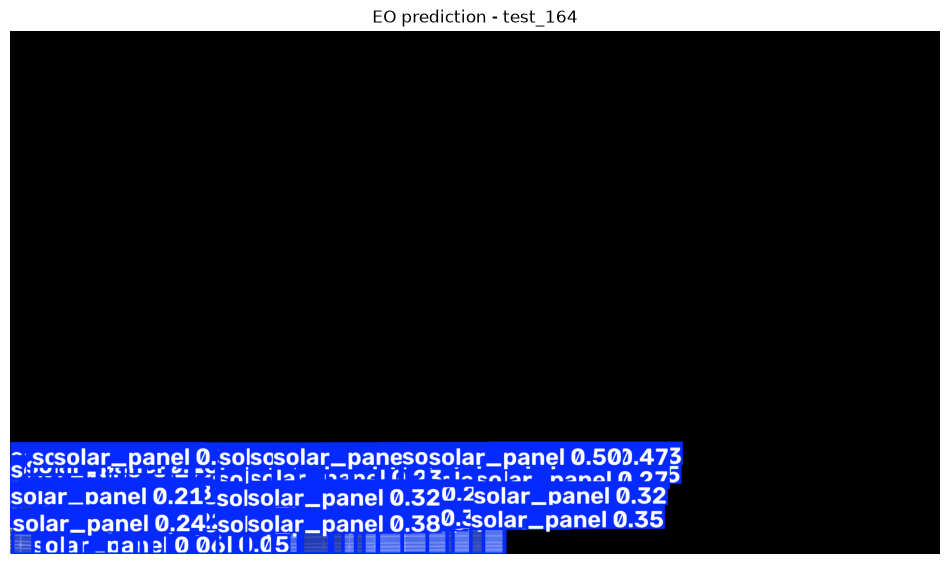


IR prediction - test_164
solar_panel: confidence=0.8475
solar_panel: confidence=0.3754
solar_panel: confidence=0.3647
solar_panel: confidence=0.2904
solar_panel: confidence=0.2853
solar_panel: confidence=0.2767
solar_panel: confidence=0.2718
solar_panel: confidence=0.2354
solar_panel: confidence=0.2347
solar_panel: confidence=0.2248
solar_panel: confidence=0.1926
solar_panel: confidence=0.1843
solar_panel: confidence=0.1769
solar_panel: confidence=0.1524
solar_panel: confidence=0.1412
solar_panel: confidence=0.1412
solar_panel: confidence=0.1347
solar_panel: confidence=0.1265
solar_panel: confidence=0.1249
solar_panel: confidence=0.1178
solar_panel: confidence=0.1086
solar_panel: confidence=0.0985
solar_panel: confidence=0.0841
solar_panel: confidence=0.0832
solar_panel: confidence=0.0812
solar_panel: confidence=0.0750
solar_panel: confidence=0.0749
solar_panel: confidence=0.0738
solar_panel: confidence=0.0725
solar_panel: confidence=0.0706
solar_panel: confidence=0.0667
solar_panel: 

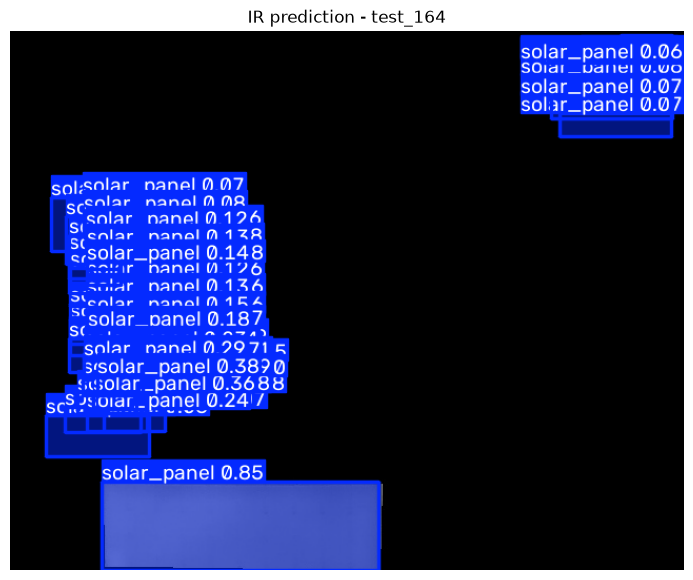

In [10]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")

EO_MODEL = DATA_ROOT / "outputs/runs/eo_baseline/weights/last.pt"
IR_MODEL = DATA_ROOT / "outputs/runs/ir_baseline/weights/last.pt"

EO_IMAGE = DATA_ROOT / "9_30_test_set/test/EO/image/test_164.jpg"
IR_IMAGE = DATA_ROOT / "9_30_test_set/test/IR/image/test_164.jpg"

eo_model = YOLO(str(EO_MODEL))
ir_model = YOLO(str(IR_MODEL))

print("EO classes:", eo_model.names)
print("IR classes:", ir_model.names)

# 先用較低 confidence 觀察模型有沒有找出異常
eo_result = eo_model.predict(
    source=str(EO_IMAGE),
    imgsz=320,
    conf=0.05,
    iou=0.7,
    max_det=500,
    device="xpu:0",
    verbose=False
)[0]

ir_result = ir_model.predict(
    source=str(IR_IMAGE),
    imgsz=320,
    conf=0.05,
    iou=0.7,
    max_det=500,
    device="xpu:0",
    verbose=False
)[0]

def show_result(result, title):
    print(f"\n{title}")
    if result.boxes is None or len(result.boxes) == 0:
        print("No detections")
    else:
        for cls_id, conf in zip(
            result.boxes.cls.cpu().tolist(),
            result.boxes.conf.cpu().tolist()
        ):
            print(
                f"{result.names[int(cls_id)]}: "
                f"confidence={conf:.4f}"
            )

    plotted = result.plot()
    plotted = plotted[:, :, ::-1]

    plt.figure(figsize=(12, 7))
    plt.imshow(plotted)
    plt.title(title)
    plt.axis("off")
    plt.show()

show_result(eo_result, "EO prediction - test_164")
show_result(ir_result, "IR prediction - test_164")


In [11]:

import pandas as pd
from pathlib import Path

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
TEST_CSV = (
    DATA_ROOT
    / "evaluation_kit"
    / "author-kit_1012"
    / "test_images.csv"
)

test_df = pd.read_csv(TEST_CSV)

print("Columns:", test_df.columns.tolist())
print("Rows:", len(test_df))
print("\nFirst 10 rows:")
display(test_df.head(10))

print("\nLast 5 rows:")
display(test_df.tail())


Columns: ['filename']
Rows: 1392

First 10 rows:


,filename
0,test/EO/image/test_001.jpg
1,test/EO/image/test_002.jpg
2,test/EO/image/test_003.jpg
3,test/EO/image/test_004.jpg
4,test/EO/image/test_005.jpg
5,test/EO/image/test_006.jpg
6,test/EO/image/test_007.jpg
7,test/EO/image/test_008.jpg
8,test/EO/image/test_009.jpg
9,test/EO/image/test_010.jpg



Last 5 rows:


,filename
1387,test/IR/image/test_692.jpg
1388,test/IR/image/test_693.jpg
1389,test/IR/image/test_694.jpg
1390,test/IR/image/test_695.jpg
1391,test/IR/image/test_696.jpg


In [12]:

import json
import time
import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
TEST_ROOT = DATA_ROOT / "9_30_test_set"

KIT_ROOT = DATA_ROOT / "evaluation_kit" / "author-kit_1012"
TEST_CSV = KIT_ROOT / "test_images.csv"

EO_MODEL_PATH = DATA_ROOT / "outputs/runs/eo_baseline/weights/last.pt"
IR_MODEL_PATH = DATA_ROOT / "outputs/runs/ir_baseline/weights/last.pt"

OUTPUT_DIR = DATA_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

PROGRESS_PATH = OUTPUT_DIR / "my_submission_v1_progress.json"
FINAL_PATH = OUTPUT_DIR / "my_submission.json"

IMG_SIZE = 320
INFERENCE_CONF = 0.05
PANEL_CONF = 0.25
ANOMALY_CONF = 0.05
MAX_DET = 500

REASONS = {
    "crack": "該片模組的板體破裂，損傷不僅止於表面。",
    "hotspot": "初步研判模組板破裂造成電流傳導異常，局部電阻升高而過熱。"
}

# --------------------------------------------------
# 2. Load test list and models
# --------------------------------------------------

test_df = pd.read_csv(TEST_CSV)
filenames = test_df["filename"].tolist()

assert len(filenames) == 1392
assert len(set(filenames)) == 1392

for filename in filenames:
    assert (TEST_ROOT / filename).exists(), f"Missing: {filename}"

eo_model = YOLO(str(EO_MODEL_PATH))
ir_model = YOLO(str(IR_MODEL_PATH))

models = {
    "EO": eo_model,
    "IR": ir_model
}

print("Test images:", len(filenames))
print("EO classes:", eo_model.names)
print("IR classes:", ir_model.names)

# --------------------------------------------------
# 3. Load previous progress if available
# --------------------------------------------------

if PROGRESS_PATH.exists():
    with open(PROGRESS_PATH, "r", encoding="utf-8") as f:
        submission = json.load(f)
    print("Resuming:", len(submission), "images already processed")
else:
    submission = {}

# --------------------------------------------------
# 4. Convert segmentation polygon
# --------------------------------------------------

def convert_polygon(result, index):
    # Prefer segmentation mask polygon
    if result.masks is not None and index < len(result.masks.xy):
        polygon = np.asarray(result.masks.xy[index], dtype=np.float32)
    else:
        polygon = np.empty((0, 2), dtype=np.float32)

    # Fallback to bounding box if mask is unavailable
    if len(polygon) < 3:
        x1, y1, x2, y2 = (
            result.boxes.xyxy[index].cpu().numpy().tolist()
        )
        polygon = np.array([
            [x1, y1],
            [x2, y1],
            [x2, y2],
            [x1, y2]
        ], dtype=np.float32)

    # Simplify polygon if it exceeds the official 100-point limit
    if len(polygon) > 100:
        epsilon = 0.5
        while True:
            simplified = cv2.approxPolyDP(
                polygon.reshape(-1, 1, 2),
                epsilon,
                True
            ).reshape(-1, 2)

            if len(simplified) <= 100:
                polygon = simplified
                break

            epsilon *= 1.5

    # Ensure at least 3 points
    if len(polygon) < 3:
        return None

    # Clip coordinates to image boundaries
    h, w = result.orig_shape

    polygon[:, 0] = np.clip(polygon[:, 0], 0, w)
    polygon[:, 1] = np.clip(polygon[:, 1], 0, h)

    return [
        [round(float(x), 2), round(float(y), 2)]
        for x, y in polygon
    ]

# --------------------------------------------------
# 5. Run inference
# --------------------------------------------------

start_time = time.perf_counter()

label_counts = {
    "solar_panel": 0,
    "crack": 0,
    "hotspot": 0
}

for i, filename in enumerate(filenames, start=1):

    # Skip images already processed
    if filename in submission:
        for pred in submission[filename]:
            label_counts[pred["label"]] += 1
        continue

    modality = "EO" if "/EO/" in filename else "IR"
    model = models[modality]

    image_path = TEST_ROOT / filename

    result = model.predict(
        source=str(image_path),
        imgsz=IMG_SIZE,
        conf=INFERENCE_CONF,
        iou=0.7,
        max_det=MAX_DET,
        device="xpu:0",
        verbose=False
    )[0]

    predictions = []

    if result.boxes is not None:
        classes = result.boxes.cls.cpu().numpy()
        confidences = result.boxes.conf.cpu().numpy()

        for j, (class_id, confidence) in enumerate(
            zip(classes, confidences)
        ):
            label = result.names[int(class_id)]

            # Class-specific confidence threshold
            threshold = (
                PANEL_CONF
                if label == "solar_panel"
                else ANOMALY_CONF
            )

            if confidence < threshold:
                continue

            points = convert_polygon(result, j)

            if points is None:
                continue

            prediction = {
                "label": label,
                "points": points
            }

            # Required reason for anomaly predictions
            if label in REASONS:
                prediction["reason"] = REASONS[label]

            predictions.append(prediction)
            label_counts[label] += 1

    # Every official image key must be present,
    # even if the model predicts no objects.
    submission[filename] = predictions

    # Save checkpoint every 50 images
    if i % 50 == 0 or i == len(filenames):
        with open(PROGRESS_PATH, "w", encoding="utf-8") as f:
            json.dump(submission, f, ensure_ascii=False)

        elapsed = time.perf_counter() - start_time
        speed = i / elapsed
        remaining = (len(filenames) - i) / speed if speed > 0 else 0

        print(
            f"[{i}/{len(filenames)}] "
            f"Elapsed: {elapsed/60:.1f} min | "
            f"ETA: {remaining/60:.1f} min | "
            f"Predictions: {label_counts}"
        )

# --------------------------------------------------
# 6. Save final submission
# --------------------------------------------------

assert len(submission) == len(filenames)

with open(FINAL_PATH, "w", encoding="utf-8") as f:
    json.dump(submission, f, ensure_ascii=False)

print("\n====================================")
print("Inference completed!")
print("Total images:", len(submission))
print("Total predictions:", sum(map(len, submission.values())))
print("Class counts:", label_counts)
print("Submission:", FINAL_PATH)
print("File size:", round(FINAL_PATH.stat().st_size / 1024 / 1024, 2), "MB")
print("====================================")


Test images: 1392
EO classes: {0: 'solar_panel', 1: 'crack'}
IR classes: {0: 'solar_panel', 1: 'hotspot'}
[50/1392] Elapsed: 0.5 min | ETA: 13.9 min | Predictions: {'solar_panel': 5148, 'crack': 93, 'hotspot': 0}
[100/1392] Elapsed: 1.0 min | ETA: 13.1 min | Predictions: {'solar_panel': 9751, 'crack': 183, 'hotspot': 0}
[150/1392] Elapsed: 1.5 min | ETA: 12.6 min | Predictions: {'solar_panel': 15227, 'crack': 209, 'hotspot': 0}
WARNING NMS time limit 2.050s exceeded
[200/1392] Elapsed: 2.1 min | ETA: 12.6 min | Predictions: {'solar_panel': 21382, 'crack': 356, 'hotspot': 0}
[250/1392] Elapsed: 2.7 min | ETA: 12.2 min | Predictions: {'solar_panel': 26005, 'crack': 465, 'hotspot': 0}
WARNING NMS time limit 2.050s exceeded
[300/1392] Elapsed: 3.2 min | ETA: 11.7 min | Predictions: {'solar_panel': 31458, 'crack': 534, 'hotspot': 0}
[350/1392] Elapsed: 3.8 min | ETA: 11.3 min | Predictions: {'solar_panel': 37981, 'crack': 587, 'hotspot': 0}
[400/1392] Elapsed: 4.2 min | ETA: 10.4 min | Pred

In [15]:

import sys
import json
import subprocess
from pathlib import Path
from collections import Counter

DATA_ROOT = Path(r"C:\Users\Sharon\Downloads\VLPaicup")
KIT_ROOT = DATA_ROOT / "evaluation_kit" / "author-kit_1012"
SUBMISSION = DATA_ROOT / "outputs" / "my_submission.json"

# 1. Official checker
result = subprocess.run(
    [
        sys.executable,
        str(KIT_ROOT / "make_submission.py"),
        "--check",
        str(SUBMISSION)
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print("Return code:", result.returncode)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

# 2. Independently inspect submission
with open(SUBMISSION, "r", encoding="utf-8") as f:
    data = json.load(f)

print("\nImage keys:", len(data))
print("Total predictions:", sum(len(v) for v in data.values()))

counts = Counter()
max_objects = 0
invalid = []

for filename, predictions in data.items():
    max_objects = max(max_objects, len(predictions))

    for pred in predictions:
        counts[pred["label"]] += 1

        points = pred.get("points", [])
        if not 2 <= len(points) <= 100:
            invalid.append((filename, "invalid point count"))

        if pred["label"] in ("crack", "hotspot"):
            if not pred.get("reason"):
                invalid.append((filename, "missing reason"))

print("\nClass counts:", dict(counts))
print("Maximum objects in one image:", max_objects)
print("Invalid predictions:", len(invalid))
print("File size MB:", round(SUBMISSION.stat().st_size / 1024 / 1024, 2))

assert len(data) == 1392
assert sum(len(v) for v in data.values()) <= 400000
assert SUBMISSION.stat().st_size < 50 * 1024 * 1024
assert not invalid

print("\nIndependent checks passed!")


Return code: 0
STDOUT:
 格式檢查通過：評分程式會接受這個檔案。
  檔案大小    27.25 MB（上限 50 MB）
  影像        1392 / 1392 張
  物件        168342 個（solar_panel 167346、hotspot 0、crack 996）
通過格式檢查只代表可以被正常評分，不代表分數高低。

STDERR:
 

Image keys: 1392
Total predictions: 168342

Class counts: {'solar_panel': 167346, 'crack': 996}
Maximum objects in one image: 500
Invalid predictions: 0
File size MB: 27.25

Independent checks passed!
